# Create a Baseline Classification

*Section 6 — Change detection, notebook 1 of 5.* Previous: `05_regression/06_compare_regressors`. Next: `02_map_to_map_change`.

**You will learn:**
- how to set up a pixel classification with `rsgispy.classification.classdata` (a `ClassificationConfig`, sample extraction and a train / validation / test split);
- how to build an analysis mask from a habitat vector layer and the image valid-data mask;
- how to tune, train and apply an XGBoost classifier with `rsgispy.classification.classxgboost`;
- how to store class names and colours in a classification with `set_thematic_classes` and map it beside the image with `create_map_panels`.

**Before you start:** this notebook builds on the supervised classification in section 4 (`04_image_classification/03_supervised_pixel_classification`). Its outputs (the 1997 classification and valid-data mask) are used by notebooks 2 – 4 of this section.

**Data:** `../data/chg_data/LS5TM_19970716_vmsk_mclds_topshad_rad_srefdem_stdsref_subset.tif` (Landsat 5 TM, 1997), `../data/chg_data/training/*.geojson` (training polygons) and `../data/chg_data/mangrove_habitat.geojson`.

**Run time:** about 1 minute.

To undertake a change detection we first require a baseline classification. This notebook creates the base classification for the change analysis that follows (notebooks 2 – 4). The classification will have three classes:

1. Mangroves
2. Other-Terrestrial
3. Water

The classification will be undertaken using the XGBoost classifier.

## Datasets and Study Area

For this tutorial we will focus on the Rufiji Delta in Tanzania and on observing changes in mangrove extent.

![studysitemap.png](figures/studysitemap.png)

## 1. Define Imports

In [1]:
# Import the matplotlib plotting module and set it to work within
# a notebook environment.
%matplotlib inline

import os

import rsgispy
import rsgispy.classification.classxgboost as cxgb
from rsgispy.classification.classdata import (
    ClassificationConfig,
    ClassInfoObj,
    ImageBandInfo,
    extract_and_split_class_samples,
    write_cls_config,
)
from rsgispy.imagecalc.maths import BandDefn, band_maths
from rsgispy.imageutils.colourtable import set_thematic_classes
from rsgispy.imageutils.masking import gen_valid_mask
from rsgispy.imageutils.rasterise import rasterise_vec_lyr
from rsgispy.mapping.layout import MapPanel, create_map_panels

## 2. Define Input Data and Directories

In [2]:
# All outputs are written under the section's outputs folder.
out_dir = os.path.join("outputs", "baseline_cls")
os.makedirs(out_dir, exist_ok=True)

# File path to the input Landsat 5 image from 1997.
input_img = (
    "../data/chg_data/LS5TM_19970716_vmsk_mclds_topshad_rad_srefdem_stdsref_subset.tif"
)

# The image bands to use as classification features, with a name for each.
img_band_info = [
    ImageBandInfo(
        input_img,
        name="ls97",
        bands=[1, 2, 3, 4, 5, 6],
        band_names=["Blue", "Green", "Red", "NIR", "SWIR1", "SWIR2"],
    )
]

## 3. Define Training Samples and Class Colours

Each class has an output pixel value (`out_id`), a vector layer of training polygons and a colour, which is written into the colour table of the output classification.

**RSGISLib users:** `ClassVecSamplesInfoObj` (and setting `red` / `green` / `blue` on the returned `ClassInfoObj`s) is replaced by one `ClassInfoObj` per class in a `ClassificationConfig`. The samples are written to Parquet tables rather than HDF5 files.

In [3]:
class_info = {
    "mangroves": ClassInfoObj(
        out_id=1,
        vec_file="../data/chg_data/training/mangroves.geojson",
        colour=(0, 255, 0),
    ),
    "other_terrestrial": ClassInfoObj(
        out_id=2,
        vec_file="../data/chg_data/training/other_terrestrial.geojson",
        colour=(180, 180, 180),
    ),
    "water": ClassInfoObj(
        out_id=3,
        vec_file="../data/chg_data/training/water.geojson",
        colour=(0, 0, 255),
    ),
}

cls_cfg = ClassificationConfig(img_band_info, class_info)

# Save the configuration so it can be reused (e.g., to apply the model later).
cls_cfg_file = os.path.join(out_dir, "cls_config.json")
write_cls_config(cls_cfg_file, cls_cfg)
print(cls_cfg.get_class_names_lut())

{1: 'mangroves', 2: 'other_terrestrial', 3: 'water'}


## 4. Extract Training, Validation and Testing Samples

`extract_and_split_class_samples` reads the image pixel values under the training polygons of each class and splits them into training, validation and testing tables. Large classes are first capped at `max_cls_smpls` samples so that the classes are balanced and the training is quick; 20 % of the samples are kept for validation (used to tune the classifier) and 20 % for testing (an independent accuracy check).

In [4]:
train_file = os.path.join(out_dir, "train.parquet")
valid_file = os.path.join(out_dir, "valid.parquet")
test_file = os.path.join(out_dir, "test.parquet")

train_df, test_df, valid_df = extract_and_split_class_samples(
    cls_cfg,
    test_prop=0.2,
    valid_prop=0.2,
    out_train_file=train_file,
    out_test_file=test_file,
    out_valid_file=valid_file,
    max_cls_smpls=20000,
    rnd_seed=42,
    use_pbar=False,
)

## 5. Number of Samples

Check the number of samples there are per class in each of the training, validation and testing sets.

In [5]:
for name, smpls_df in (("train", train_df), ("valid", valid_df), ("test", test_df)):
    print(name, smpls_df["class_name"].value_counts().to_dict())

train {'mangroves': 12000, 'other_terrestrial': 12000, 'water': 12000}
valid {'mangroves': 4000, 'other_terrestrial': 4000, 'water': 4000}
test {'mangroves': 4000, 'other_terrestrial': 4000, 'water': 4000}


## 6. Define Classification Mask

Mangroves have a unique habitat being close to the coastline with a low elevation. It is therefore not appropriate to look to classify mangroves in other locations. In this case we will use a mangrove habitat mask similar to that used as part of the global mangrove watch study (Bunting et al., 2018).

### 6.1 Rasterise Mangrove Habitat Mask

In [6]:
vec_file = "../data/chg_data/mangrove_habitat.geojson"

mng_hab_msk_img = os.path.join(out_dir, "mangrove_habitat.tif")

# Burn the value 1 into a raster on the same pixel grid as the input image.
rasterise_vec_lyr(vec_file, None, input_img, mng_hab_msk_img, burn_val=1, use_pbar=False)

### 6.2 Create Landsat Valid Mask

We need to check which pixels are valid within the Landsat image so only those with image pixel values are being used.

In [7]:
vld_pxl_msk_img = os.path.join(out_dir, "LS5TM_19970716_vmsk.tif")

# Calculate the valid mask (1 where the image has data, 0 elsewhere). The
# output is marked as a thematic image and has statistics calculated.
gen_valid_mask(input_img, vld_pxl_msk_img, no_data_val=0.0, use_pbar=False)

### 6.3 Merge Habitat and Valid Pixel Masks

In [8]:
mng_scn_hab_msk_img = os.path.join(out_dir, "LS5TM_19970716_vmsk_mng_hab.tif")

# Create Mask for pixels which are valid and within the mangrove habitat mask.
band_defns = [
    BandDefn("vld", vld_pxl_msk_img, 1),
    BandDefn("hab", mng_hab_msk_img, 1),
]
band_maths(
    mng_scn_hab_msk_img,
    "(vld==1)&&(hab==1)?1:0",
    band_defns,
    datatype=rsgispy.TYPE_8UINT,
    use_pbar=False,
)

# The output is a binary mask so it is a thematic dataset: mark it as
# thematic, give class 1 a name and colour (0 is no data) and calculate
# statistics and pyramids, in one call.
set_thematic_classes(mng_scn_hab_msk_img, {1: ("Mangrove habitat", (0, 160, 0))})

**RSGISLib users:** `rastergis.pop_rat_img_stats` and `rastergis.set_class_names_colours` are replaced by `imageutils.colourtable.set_thematic_classes`, which marks the image as thematic, writes the class colours to the colour table, stores the class names in the image (a GeoTIFF band tag, read back with `get_thematic_classes`) and builds statistics and pyramids. rsgispy does not use raster attribute tables (RATs). `imageutils.stats.pop_thmt_img_stats` does the same without the names.

### 6.4 Visualise Mask

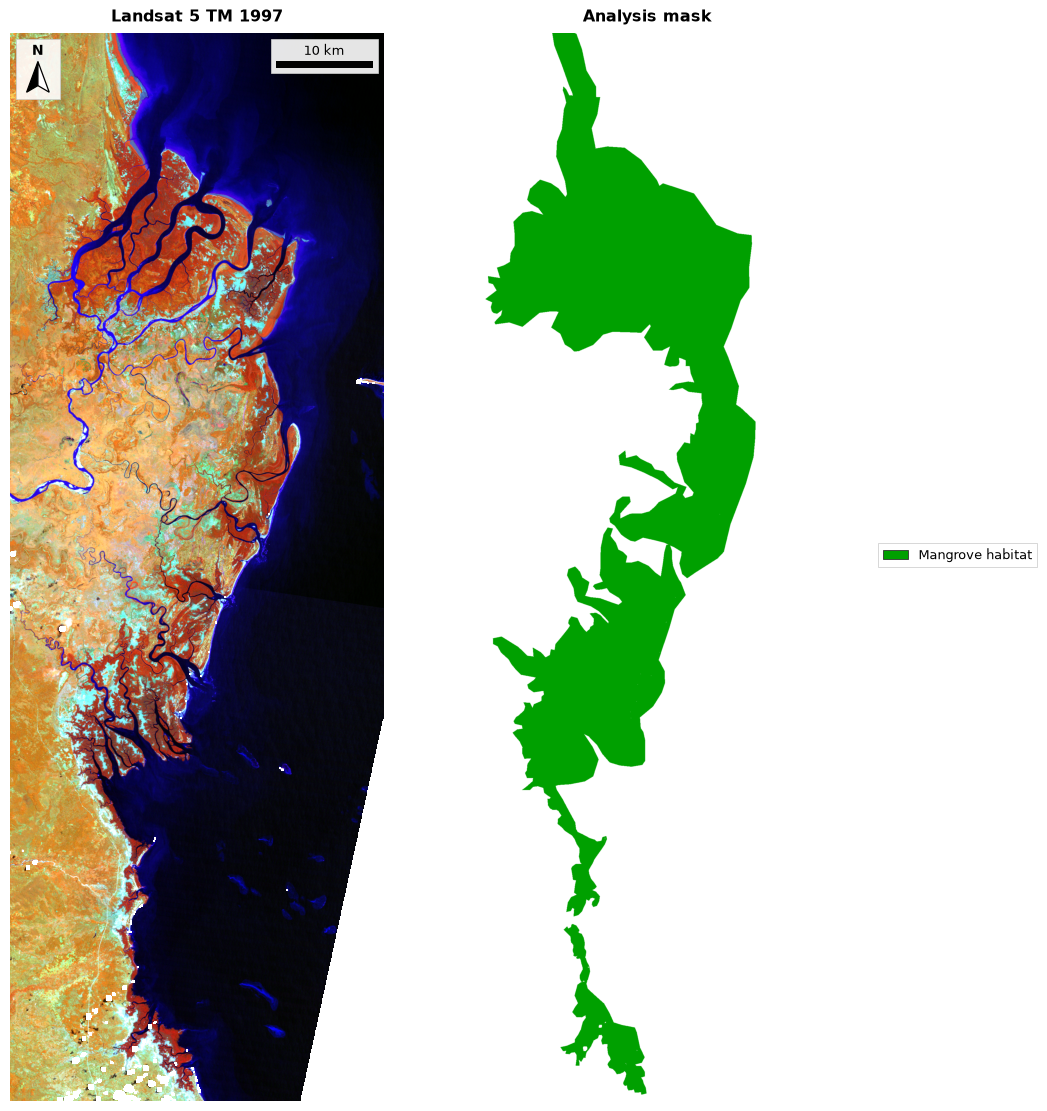

In [9]:
# The image and the mask side by side, sharing one scale bar and north
# arrow; the legend uses the class name stored in the mask.
fig, axs = create_map_panels(
    [
        MapPanel("rgb", input_img, bands=[4, 5, 3], title="Landsat 5 TM 1997"),
        MapPanel("thematic", mng_scn_hab_msk_img, title="Analysis mask"),
    ],
    figsize=(9, 11),
)

## 7. Train Classifier

In this example, an XGBoost classifier is used and its parameters are optimised using a Bayesian optimisation (with [Optuna](https://optuna.org)). Each trial trains a model with a different set of parameters and scores it on the validation samples. To keep the run time short only 10 trials are used here; with your own data you would usually use more (e.g., 50 – 100).

Once the best parameters have been found, the final model is trained and its accuracy checked on the independent test samples.

**RSGISLib users:** `train_opt_xgboost_multiclass_classifier` is replaced by `optimise_xgboost_multiclass_classifier` (parameter search) followed by `train_xgboost_multiclass_classifier` (train, test and save).

In [10]:
# Find the best XGBoost parameters.
xgb_model = cxgb.optimise_xgboost_multiclass_classifier(
    cls_cfg,
    train_file,
    valid_data=valid_file,
    n_trials=10,
    early_stopping_rounds=20,
    rnd_seed=42,
    use_pbar=False,
)

# Train the final classifier, test it and save it.
out_mdl_file = os.path.join(out_dir, "cls_xgb_mdl.json")
_, xgb_metrics = cxgb.train_xgboost_multiclass_classifier(
    cls_cfg,
    train_file,
    test_data=test_file,
    xgb_classifier=xgb_model,
    out_model_file=out_mdl_file,
)
print({k: round(v, 3) for k, v in xgb_metrics.items()})

{'train_accuracy': 0.996, 'train_bal_accuracy': 0.996, 'train_f1_macro': 0.996, 'train_cohen_kappa': 0.994, 'test_accuracy': 0.994, 'test_bal_accuracy': 0.994, 'test_f1_macro': 0.994, 'test_cohen_kappa': 0.991}


## 8. Apply Classifier

The classifier is applied to the pixels within the mask (where the mask is 1). The output image gets a colour table from the class colours defined in step 3. The class names are then stored in the image with `set_thematic_classes`, so the maps here and in the following notebooks can label the classes without being given the names.

In [11]:
# Apply the classifier to the image
out_cls_img = os.path.join(out_dir, "base_1997_class_img.tif")
cxgb.apply_xgboost_multiclass_classifier(
    cls_cfg,
    out_mdl_file,
    mng_scn_hab_msk_img,
    1,
    output_img=out_cls_img,
    use_pbar=False,
)

# Store the class names (and colours) in the classification.
set_thematic_classes(
    out_cls_img,
    {cls.out_id: (name, cls.colour) for name, cls in class_info.items()},
)

## 9. Visualise Classification Result

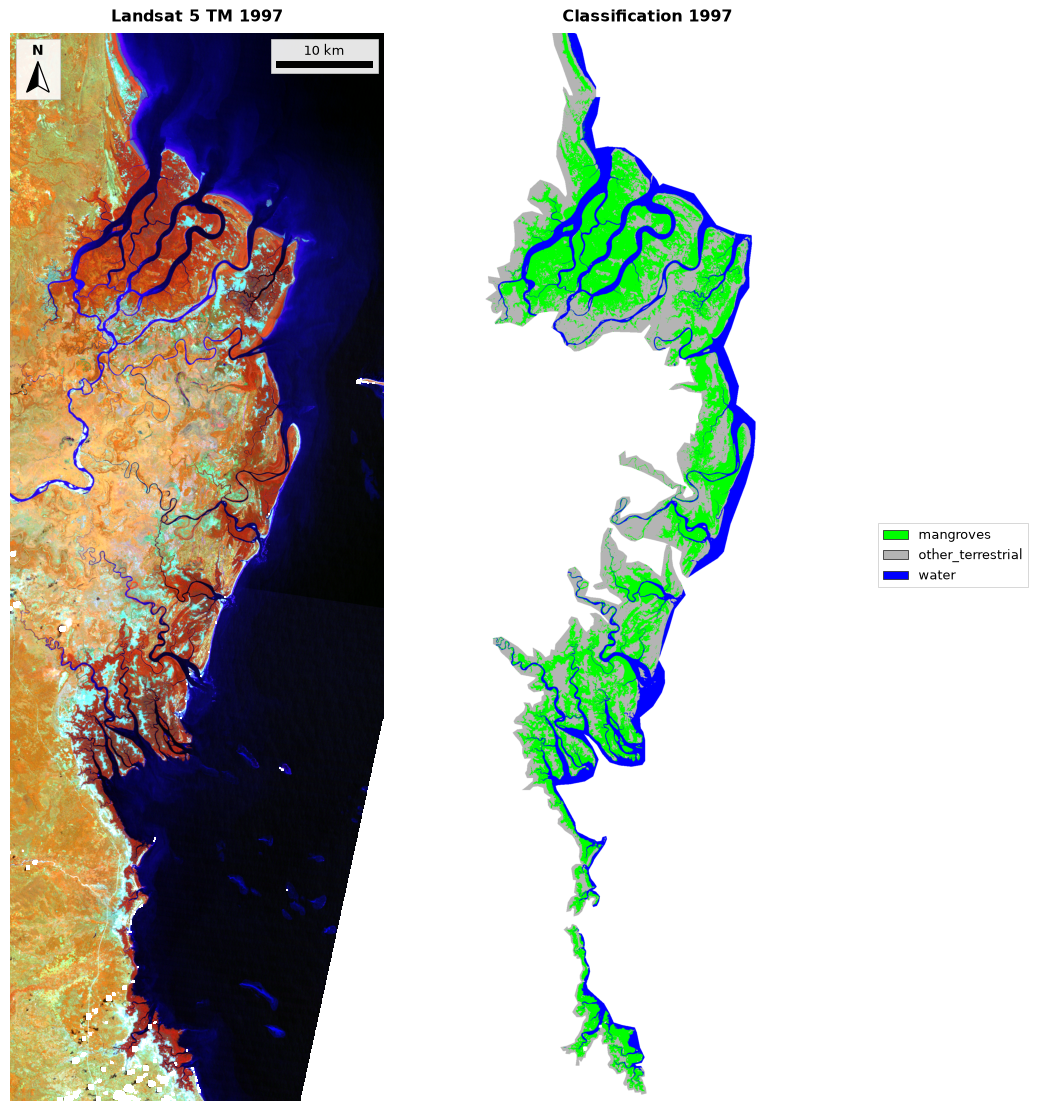

In [12]:
fig, axs = create_map_panels(
    [
        MapPanel("rgb", input_img, bands=[4, 5, 3], title="Landsat 5 TM 1997"),
        MapPanel("thematic", out_cls_img, title="Classification 1997"),
    ],
    figsize=(9, 11),
)

## 10. Visualise Subset

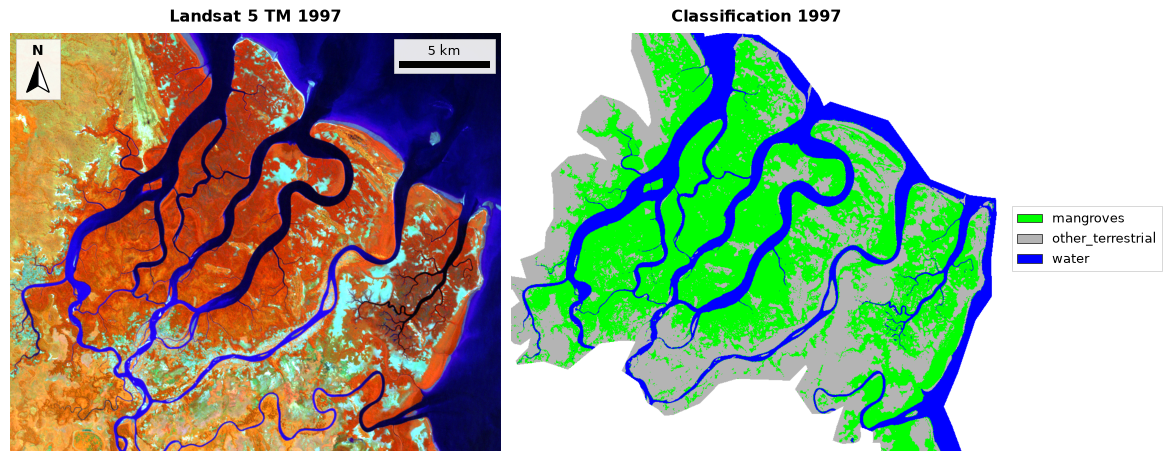

In [13]:
sub_bbox = [523000, 550000, -877000, -854000]

fig, axs = create_map_panels(
    [
        MapPanel("rgb", input_img, bands=[4, 5, 3], title="Landsat 5 TM 1997"),
        MapPanel("thematic", out_cls_img, title="Classification 1997"),
    ],
    bbox=sub_bbox,
)